<a href="https://colab.research.google.com/github/sanjogsawant346-ops/CSL701-51_Machine-Learning-Lab/blob/main/ML_Experiment_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 10


Student Name : Sanjog Sawant



Roll Number : CS51



### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

# Load dataset
df = pd.read_csv("/content/archive (10).zip")

print("Dataset shape:", df.shape)
print(df.head())

print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

Selected features:
['Annual Income (k$)', 'Spending Score (1-100)']

Scaled data:
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


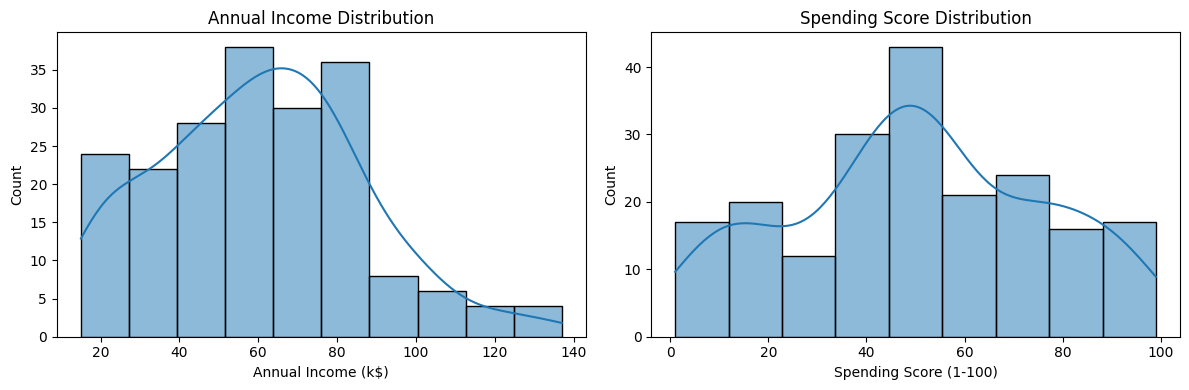

In [ ]:

# Select required features
features = ["Annual Income (k$)", "Spending Score (1-100)"]

X = df[features].copy()

# Handle missing values
X = X.apply(pd.to_numeric, errors="coerce")
valid_rows = X.notna().all(axis=1)
X = X.loc[valid_rows]
df_work = df.loc[valid_rows].copy()

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Selected features:")
print(features)

print("\nScaled data:")
print(X_scaled[:5])

# Visualize original features
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(X[features[0]], kde=True, ax=axes[0])
axes[0].set_title("Annual Income Distribution")

sns.histplot(X[features[1]], kde=True, ax=axes[1])
axes[1].set_title("Spending Score Distribution")

plt.tight_layout()
plt.show()


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

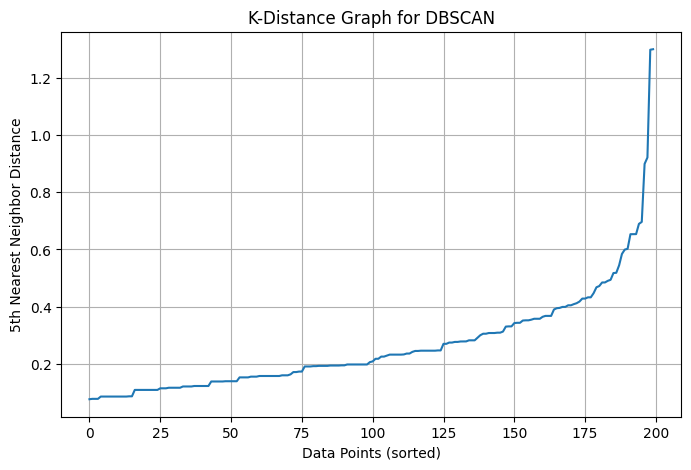

Epsilon: 0.6
Minimum Samples: 5


In [ ]:

# Set minimum samples
min_samples = 5

# Find nearest neighbors
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Sort distances to the 5th nearest neighbor
k_distances = np.sort(distances[:, -1])

# Plot k-distance graph
plt.figure(figsize=(8, 5))
plt.plot(k_distances)

plt.xlabel("Data Points (sorted)")
plt.ylabel("5th Nearest Neighbor Distance")
plt.title("K-Distance Graph for DBSCAN")
plt.grid(True)

plt.show()

# Initial epsilon value
eps = 0.6

print("Epsilon:", eps)
print("Minimum Samples:", min_samples)


# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

Cluster labels:
[-1  0]

Clustered data:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   

   Cluster  
0        0  
1        0  
2        0  
3        0  
4        0  


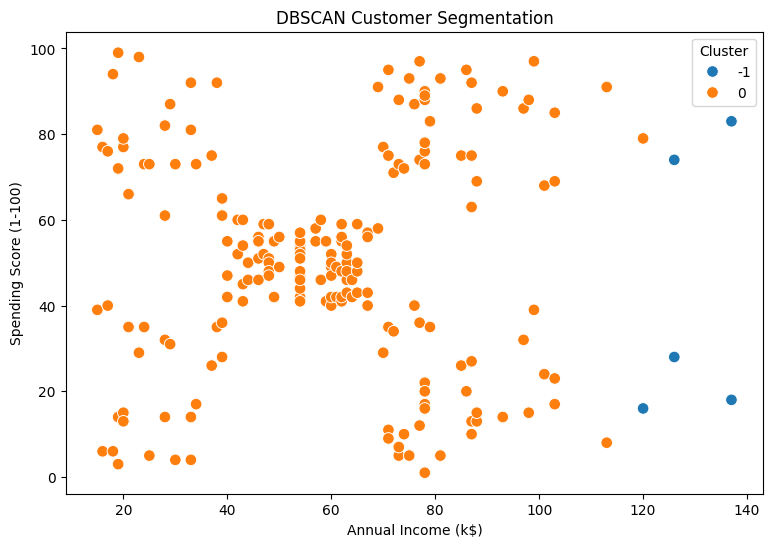

In [ ]:

# Create DBSCAN model
dbscan = DBSCAN(
    eps=eps,
    min_samples=min_samples
)

# Fit the model and predict cluster labels
labels = dbscan.fit_predict(X_scaled)

# Add cluster labels to the dataset
df_clustered = df_work.copy()
df_clustered["Cluster"] = labels

print("Cluster labels:")
print(np.unique(labels))

print("\nClustered data:")
print(df_clustered.head())

# Visualize clusters
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df_clustered,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=70
)

plt.title("DBSCAN Customer Segmentation")
plt.legend(title="Cluster")
plt.show()


# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [ ]:

# Count clusters and noise points
labels_array = np.asarray(labels)

cluster_labels = set(labels_array) - {-1}
n_clusters = len(cluster_labels)

n_noise = np.sum(labels_array == -1)
noise_percentage = (n_noise / len(labels_array)) * 100

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)
print(f"Noise percentage: {noise_percentage:.2f}%")

# Calculate Silhouette Score when valid
non_noise_mask = labels_array != -1

non_noise_labels = labels_array[non_noise_mask]
non_noise_data = X_scaled[non_noise_mask]

if (
    len(set(non_noise_labels)) >= 2
    and len(non_noise_labels) > len(set(non_noise_labels))
):
    score = silhouette_score(
        non_noise_data,
        non_noise_labels
    )
    print("Silhouette Score:", round(score, 4))
else:
    print(
        "Silhouette Score cannot be calculated. "
        "At least two non-noise clusters are required."
    )


Number of clusters: 1
Number of noise points: 5
Noise percentage: 2.50%
Silhouette Score cannot be calculated. At least two non-noise clusters are required.


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

In [ ]:

# Calculate cluster statistics
summary = df_clustered.groupby("Cluster").agg(
    Customer_Count=("Cluster", "size"),
    Average_Annual_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

print("Customer Segment Summary:")
print(summary)

# Interpret the clusters
for cluster_id, row in summary.iterrows():
    if cluster_id == -1:
        print("\nNoise / Outliers")
    else:
        print(f"\nCluster {cluster_id}")

    print("Number of customers:", int(row["Customer_Count"]))
    print(
        "Average annual income:",
        row["Average_Annual_Income"]
    )
    print(
        "Average spending score:",
        row["Average_Spending_Score"]
    )

# Save results
df_clustered.to_csv(
    "Mall_Customers_DBSCAN_Results.csv",
    index=False
)

summary.to_csv("DBSCAN_Cluster_Summary.csv")

print("\nResults saved successfully.")


Customer Segment Summary:
         Customer_Count  Average_Annual_Income  Average_Spending_Score
Cluster                                                               
-1                    5                  129.2                   43.80
 0                  195                   58.8                   50.36

Noise / Outliers
Number of customers: 5
Average annual income: 129.2
Average spending score: 43.8

Cluster 0
Number of customers: 195
Average annual income: 58.8
Average spending score: 50.36

Results saved successfully.


# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.